This notebook can take up to 6 hours to run on intel core i7, with 1000 instaces of data.

In [28]:
#utils
import pandas as pd
import numpy as np
import contextlib
import os
import warnings
from scipy.stats import norm
import sys

#visualization libraries
import matplotlib.pyplot as plt

#machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, auc
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve

#models 

from models.AutoEncoder import Autoencoder
from models.ContractiveAutoEncoder import ContractiveAutoEncoder
from models.VariationalAutoencoder import VariationalAutoEncoder
from models.alad.ALAD import ALAD


warnings.filterwarnings("ignore")

In [29]:
df = pd.read_csv('SimulationData.csv')
df = df.head(1000)
df

,isghost,chi2,nb_hits,qop,tx,ty,x,y,z,trk_best_pt,...,trk_kalman_ipx,trk_kalman_ipy,trk_ndof,trk_ndofT,trk_ndofV,trk_velo_docaz,trk_velo_ip,trk_velo_ip_chi2,trk_velo_ipx,trk_velo_ipy
0,0,5.864667,23,0.000023,-0.028342,-0.003546,0.000634,-0.005067,78.771744,1268.343506,...,-0.009011,-0.009870,10.0,3.809383e+09,0.0,0.053306,0.056174,0.229229,-0.011182,-0.055074
1,0,9.498068,22,-0.000089,-0.035880,-0.009850,-0.019085,0.069519,80.973526,418.299805,...,0.052025,0.087872,12.0,3.809383e+09,0.0,0.006958,0.108953,0.530859,0.106834,0.021767
2,0,8.184366,22,-0.000057,-0.016312,-0.009838,-0.017012,0.028208,92.175171,334.801575,...,0.031604,0.027265,8.0,3.809383e+09,0.0,0.018347,0.206216,3.245677,0.166305,0.121998
3,0,86.617691,22,-0.000032,-0.019891,-0.019328,-1.889721,1.944762,120.151199,869.915710,...,0.000000,0.000000,10.0,3.809383e+09,0.0,2.375821,2.491225,460.366547,-1.065801,2.252785
4,0,7.774436,27,-0.000066,-0.018290,-0.012823,1.265772,-1.805411,-33.804581,337.069244,...,1.973482,-1.313249,18.0,3.809383e+09,0.0,2.292284,2.458901,270.415924,2.037640,-1.377404
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0,9.657281,23,-0.000176,0.107537,-0.106182,0.000238,0.000240,14.249619,846.628540,...,-0.023231,-0.008009,12.0,3.809383e+09,0.0,0.017922,0.058116,0.064387,-0.052423,0.026583
996,0,0.331296,19,0.000143,0.083397,0.136177,-1.293904,0.792406,-16.147064,1099.568726,...,-1.314746,0.693226,4.0,3.809383e+09,0.0,1.474573,1.458521,46.371105,-1.301789,0.697731
997,0,2.470742,22,0.000147,0.198717,-0.064938,-0.001387,-0.004248,-16.773180,1389.811035,...,0.017627,0.003391,8.0,3.809383e+09,0.0,0.032935,0.045401,0.138506,-0.020783,0.041469
998,0,93.424606,22,-0.000171,0.222166,0.117708,0.076876,-0.145100,-16.549612,1426.536011,...,0.043707,-0.183353,8.0,3.809383e+09,0.0,0.065692,0.066526,0.200032,-0.047502,0.049484


In [30]:
target_feature = "isghost"
columns = df.drop(columns=target_feature).columns
#instantiate two more datasets one to contain the normal data
#and the other to hold the anomalous instances
train_normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

In [31]:
#also instantiate a dataframe to carry all the features
#and a second one to instead contain the target variable
def get_normal_data(df):
    df = df.sample(frac=1)
    features = df.drop([target_feature], axis=1)
    label = df[target_feature]

    #the stratify parameter here is set to be "isghost" meaning that the 
    #proportions of ghost and normal tracks in both train and test datasets
    #will be kept the same...
    x_train, x_test, y_train, y_test = train_test_split(
        features, label, test_size=0.2, stratify=label
    )

    #remember that at least for the autoencoders we're gonna use just the 
    #normal instances during the training phase so we have to filter those in x_train
    train_index = y_train[y_train == 0].index
    train_normal_data = x_train.loc[train_index]

    return train_normal_data, x_train, y_train, x_test, y_test

In [32]:
def standardize_normalize(train_x, normal_train_data, test_data):


    non_zero_cols = train_x.columns[(train_x != 0).any()]

    # Calculate mean and standard deviation only for non-zero columns
    mean = train_x[non_zero_cols].mean()
    std = train_x[non_zero_cols].std() + sys.float_info.min

    # Standardize the non-zero columns in normal_train_data, train_x, and test_data
    normal_train_data[non_zero_cols] = (normal_train_data[non_zero_cols] - mean) / std
    train_x[non_zero_cols] = (train_x[non_zero_cols] - mean) / std
    test_data[non_zero_cols] = (test_data[non_zero_cols] - mean) / std

    # Create a scaler and apply Min-Max scaling to all columns
    scaler = MinMaxScaler()
    normal_train_data = scaler.fit_transform(normal_train_data)
    train_x = scaler.transform(train_x)
    test_data = scaler.transform(test_data)
    
    return train_x, normal_train_data, test_data

In [33]:
def get_data():

    train_normal_data, x_train, _, x_test, y_test = get_normal_data(df.sample(frac=1).reset_index(drop=True))
    _, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)

    return train_normal_data, x_test, y_test

In [34]:
train_normal_data, x_train, y_train, x_test, y_test = get_normal_data(df)
x_train, train_normal_data, x_test = standardize_normalize(x_train, train_normal_data, x_test)

INPUT_DIM = train_normal_data.shape[1]
ENCODING_DIM = 3
LEARNING_RATE = 0.001

In [35]:
train_normal_data

array([[1.20894598e-02, 6.87500000e-01, 5.45135242e-01, ...,
        1.78067166e-05, 5.56302741e-01, 3.67426807e-01],
       [1.65542865e-03, 4.37500000e-01, 4.68464371e-01, ...,
        3.03752406e-05, 5.61499308e-01, 3.66718536e-01],
       [1.15643817e-02, 7.50000000e-01, 5.36553820e-01, ...,
        2.02499676e-05, 5.56502259e-01, 3.73596252e-01],
       ...,
       [1.43633212e-03, 6.25000000e-02, 5.39179379e-01, ...,
        4.85042496e-04, 5.55586993e-01, 3.80355864e-01],
       [1.06756455e-02, 4.37500000e-01, 2.66258174e-01, ...,
        1.85971499e-04, 5.57548972e-01, 3.59971620e-01],
       [6.54993971e-03, 3.75000000e-01, 3.35834612e-01, ...,
        1.72195296e-04, 5.55623221e-01, 3.77295547e-01]])

In [36]:
def build_models():

    ae = Autoencoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
    cae = ContractiveAutoEncoder(INPUT_DIM, ENCODING_DIM, lambda_=0.01, learning_rate = LEARNING_RATE)
    vae = VariationalAutoEncoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
    alad = ALAD(input_dim=INPUT_DIM, latent_dim=ENCODING_DIM, learning_rate=LEARNING_RATE)

    ae.build(input_shape=(train_normal_data.shape))
    cae.build(input_shape=(train_normal_data.shape))
    vae.build(input_shape=(train_normal_data.shape))
    
    return ae, cae, vae, alad

In [37]:

def avgNestedLists(nested_vals):
    """
    Averages a 2-D array and returns a 1-D array of all of the columns
    averaged together, regardless of their dimensions.
    """
    output = []
    maximum = 0
    for lst in nested_vals:
        if len(lst) > maximum:
            maximum = len(lst)
    for index in range(maximum): # Go through each index of longest list
        temp = []
        for lst in nested_vals: # Go through each list
            if index < len(lst): # If not an index error
                temp.append(lst[index])
        output.append(np.nanmean(temp))
    return output

In [38]:
def transfer_weights(original_model, target_model, is_alad=False):


    #this is to check if the model is VAE
    #if so we want to skip the first layer 
    #for encoder and decoder, as it's an Input layer
    #not shared by the other networks
    
    target_encoder_layers = target_model.layers
    if target_model.name == "VAE":
        target_encoder_layers = target_model.layers[1:]

    target_decoder_layers = target_model.layers
    if target_model.name == "VAE":
        target_decoder_layers = target_model.layers[1:]

    #go throught the encoer weights 
    for source_layer, target_layer in zip(original_model.encoder.layers, target_encoder_layers):
        if target_layer.name != "bottleneck" and isinstance(target_layer, tf.keras.layers.InputLayer):
            target_layer.set_weights(source_layer.get_weights())

    #alad only has an encoder
    if not is_alad:
        #go throught the decoder layers 
        for source_layer, target_layer in zip(original_model.encoder.layers, target_decoder_layers):
            if target_layer.name != "final"  and isinstance(target_layer, tf.keras.layers.InputLayer):
                target_layer.set_weights(source_layer.get_weights())

    return target_model

In [39]:
import numpy as np
from sklearn.metrics import roc_curve, auc
from scipy import stats


def mean_and_confidence(model, threshold_function, alpha=0.95, iterations=30, transfer=False, epochs=5):
   

    #initialize all the containers for teh metrics to track
    list_fpr = []
    list_tpr = []
    list_auc = []
    list_pr = []

    #precision and recall will be used for 
    #the curve but also as general parameters 
    list_precision_curve = []
    list_recall_curve = []

    #classification metrics 
    list_accuracy = []
    list_precision = []
    list_recall = []
    list_f1 = []

    list_training_time = []
    histories = []


    flag = "tranfer" if transfer else "no transfer"

    model.save_weights('saved_weights/my_model' + flag + model.model_name)
        

    if transfer:
        ae = Autoencoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
        ae.build(input_shape=(train_normal_data.shape))
        ae.save_weights('saved_weights/my_model' + flag + ae.model_name)
    
    for _ in range(iterations):

        x_train, x_test, y_test = get_data()

        if transfer:
            
            history_ae, training_time_ae = ae.train(x_train, epochs=50, batch_size=30, validation_split=0.2)
            #tranfer_learning here
            model = transfer_weights(ae, model)

        history, training_time = model.train(x_train, epochs=epochs, batch_size=30, validation_split=0.2)
        
        if isinstance(model, Autoencoder):
            history = history.history['loss']
        else:
            history = history
            
        ###time each model 
        threshold = threshold_function(x_train, x_test, y_test)
        predictions = model.find_anomalies(x_test, threshold)
        accuracy, precision, recall, f1 = model.classification_metrics(y_test, predictions)

        #re-set all the trainable variables of the model
        model.load_weights('saved_weights/my_model' + flag + model.model_name)
        
        fpr_ae, tpr_ae, _ = roc_curve(y_test, predictions)
        auc_ae = auc(fpr_ae, tpr_ae)
        list_fpr.append(fpr_ae)
        list_tpr.append(tpr_ae)
        

        precision_curve, recall_curve, _ = precision_recall_curve(y_test, predictions)
        pr = auc(np.sort(precision_curve), np.sort(recall_curve))
        list_pr.append(pr)
        list_precision_curve.append(precision_curve)
        list_recall_curve.append(recall_curve)


        list_accuracy.append(accuracy)
        list_precision.append(precision)
        list_recall.append(recall)
        list_f1.append(f1)
        list_training_time.append(training_time)
        list_auc.append(auc_ae)
        histories.append(history)

    #roc_curve can return different sized arrays
    #this means that ther needs to be a custom function
    #to compute the mean 
    avg_fpr = avgNestedLists(list_fpr)
    avg_tpr = avgNestedLists(list_tpr)
    avg_precision_curve = avgNestedLists(list_precision_curve)
    avg_recall_curve = avgNestedLists(list_recall_curve)
    avg_acc = np.mean(list_accuracy)
    avg_rec = np.mean(list_recall)
    avg_pre = np.mean(list_precision)
    avg_f1 = np.mean(list_f1)
    avg_time = np.mean(list_training_time)
    avg_auc = np.mean(list_auc)
    avg_pr = np.mean(list_pr)

    histories = avgNestedLists(histories)

    #standard deviations
    accuracy_std = np.std(list_accuracy)
    precision_std = np.std(list_precision)
    recall_std = np.std(list_recall)
    f1_std = np.std(list_f1)
    training_time_std = np.std(list_training_time)
    auc_std = np.std(list_auc)
    pr_std = np.std(list_pr)

    #how to take the "mean curve"  
    interval_acc = stats.t.interval(alpha=alpha, loc=np.mean(list_accuracy), df=len(list_accuracy)-1, scale=stats.sem(list_accuracy))
    interval_rec = stats.t.interval(alpha=alpha, loc=np.mean(list_recall), df=len(list_recall)-1, scale=stats.sem(list_recall))
    interval_pre = stats.t.interval(alpha=alpha, loc=np.mean(list_precision), df=len(list_precision)-1, scale=stats.sem(list_precision))
    interval_f1 = stats.t.interval(alpha=alpha, loc=np.mean(list_f1), df=len(list_f1)-1, scale=stats.sem(list_f1))
    interval_time = stats.t.interval(alpha=alpha, loc=np.mean(list_training_time), df=len(list_training_time)-1, scale=stats.sem(list_training_time))
    interval_auc = stats.t.interval(alpha=alpha, loc=np.mean(list_auc), df=len(list_auc)-1, scale=stats.sem(list_auc))
    interval_pr = stats.t.interval(alpha=alpha, loc=np.mean(list_pr), df=len(list_pr)-1, scale=stats.sem(list_pr))

    plt.plot(avg_fpr, avg_tpr)
    plt.plot(avg_fpr, avg_tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % avg_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve ' + model.model_name + " " + flag)
    plt.text(1.05, 0.5, flag, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.legend(loc="lower right")
    plt.savefig('images/Average ROC' + model.model_name + flag)
    plt.close()

    plt.plot(avg_precision_curve, avg_recall_curve)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve ' + model.model_name + " " + flag)
    plt.text(1.05, 0.5, flag, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.savefig('images/Average Precision Recall ' + model.model_name + " " + flag)
    plt.close()


    averages = {
        "Average FPR": avg_fpr,
        "Average TPR": avg_tpr,
        "Average precision curve": avg_precision_curve,
        "Average recall curve": avg_recall_curve,
        "Average accuracy": avg_acc,
        "Average recall": avg_rec,
        "Average precision": avg_pre,
        "Average F-1": avg_f1,
        "Average training time": avg_time,
        "Average AUCROC": avg_auc,
        "Average AUPRC": avg_pr,
        }
    

    sigmas = {
        "STD accuracy": accuracy_std,
        "STD recall": recall_std,
        "STD precision": precision_std,
        "STD F-1": f1_std,
        "STD training time": training_time_std,
        "STD AUC": auc_std,
        "STD AUPRC": pr_std,
    }

    
    intervals = {
        "Interval accuracy": interval_acc,
        "Interval recall": interval_rec,
        "Interval precision": interval_pre,
        "Interval F-1": interval_f1,
        "Interval training time": interval_time,
        "Interval AUC": interval_auc,
        "Interval AUCPR": interval_pr,
        }
    
    return [averages, intervals, sigmas, histories]

In [40]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    ae, cae, vae, alad = build_models()
            
    alad_std = mean_and_confidence(alad, alad.find_best_deviations_threshold, alpha=0.95)
    ae_std = mean_and_confidence(ae, ae.find_best_deviations_threshold, alpha=0.95)
    cae_std = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95)
    vae_std = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95)

    

In [41]:
def plot_training_loss(hist_ae=None, hist_cae=None, hist_vae=None, hist_alad=None):
    
    if hist_ae is not None:
        plt.plot(hist_ae, label='AE Loss')
    
    plt.plot(hist_cae, label='CAE Loss')
    plt.plot(hist_vae, label='VAE Loss') 
    plt.plot(hist_alad, label='ALAD Loss')

    plt.yscale('log')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training Loss AE')
    plt.legend()
    
    plt.savefig('images/All models training loss ')
    plt.show()   
        

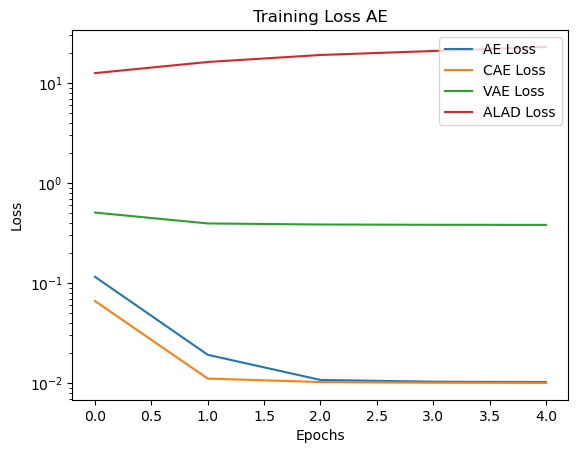

In [42]:
plot_training_loss(ae_std[3], cae_std[3], vae_std[3], alad_std[3])

In [63]:
def print_metrics(val):
     
    means = dict(list(val[0].items())[-7:])
    intervals = val[1]


    names = ["Accuracy", "Recall", "Precision", "F-1", "Training time", "AUCROC", "AUPRC"]


    df = pd.DataFrame({
        'Metric': names,
        'Mean': list(means.values()),
        'Interval': [intervals[key] for key in intervals.keys()]
    })

    print(df)

In [62]:
print("_________________ALAD________________")
print_metrics(alad_std)
print("_________________AE________________")
print_metrics(ae_std)
print("_________________CAE________________")
print_metrics(cae_std)
print("_________________VAE________________")
print_metrics(vae_std)

_________________ALAD________________
{'Average accuracy': 0.963, 'Average recall': 0.014285714285714285, 'Average precision': 0.042777777777777776, 'Average F-1': 0.01739766081871345, 'Average training time': 3.827404522895813, 'Average AUCROC': 0.5058475203552923, 'Average AUPRC': 0.4697539682539682}
          Metric      Mean                                        Interval
0       Accuracy  0.963000        (0.9594440116752478, 0.9665559883247521)
1         Recall  0.014286  (-0.0019909832876669874, 0.030562411859095556)
2      Precision  0.042778     (-0.02628569652907449, 0.11184125208463004)
3            F-1  0.017398   (-0.0036658594749233893, 0.03846118111235029)
4  Training time  3.827405         (3.7522385099457316, 3.902570535845894)
5         AUCROC  0.505848        (0.4990365459654578, 0.5126584947451268)
6          AUPRC  0.469754      (0.44130307889214626, 0.49820485761579014)
_________________AE________________
{'Average accuracy': 0.8746666666666665, 'Average recall': 0

In [64]:
def roc_curve_models(avg_ae=None, avg_cae=None, avg_vae=None, fun_name=None, avg_alad=None, transfer="no transfer", all_models=" all models"):

    if avg_ae is not None:
        fpr_ae = avg_ae["Average FPR"]
        tpr_ae = avg_ae["Average TPR"]
        auc_ae = avg_ae["Average AUCROC"]

    fpr_cae = avg_cae["Average FPR"]
    tpr_cae = avg_cae["Average TPR"]
    fpr_vae = avg_vae["Average FPR"]
    tpr_vae = avg_vae["Average TPR"]
    fpr_alad = avg_alad["Average FPR"]
    tpr_alad = avg_alad["Average TPR"]
    
    auc_cae = avg_cae["Average AUCROC"]
    auc_vae = avg_vae["Average AUCROC"]
    auc_alad = avg_alad["Average AUCROC"]


    x = np.linspace(0, 1, 10)

    # Compute y values (y = x)
    y = x

    # Plot the diagonal dotted line
    plt.plot(x, y, linestyle=':', color='purple')
    
    if avg_ae is not None:
        plt.plot(fpr_ae, tpr_ae, label='AE (AUC = {})'.format(round(auc_ae, 2)))

    plt.plot(fpr_cae, tpr_cae, label='CAE (AUC = {})'.format(round(auc_cae, 2)))
    plt.plot(fpr_vae, tpr_vae, label='VAE (AUC = {})'.format(round(auc_vae, 2)))
    plt.plot(fpr_alad, tpr_alad, label='ALAD (AUC = {})'.format(round(auc_alad, 2)))

    # Adding labels and legends
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) ' + transfer)
    plt.text(1.05, 0.5, fun_name, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.legend()
    plt.savefig('images/All models ROC ' + transfer + all_models)

    # Display the plot
    plt.show()

In [66]:
def pr_models(avg_ae=None, avg_cae=None, avg_vae=None, fun_name=None, avg_alad=None, transfer= "no transfer", all_models=" all models"):    
    
    #plot all the precision-recall losses together
    if avg_ae is not None:
        precision_ae, recall_ae, = avg_ae["Average precision curve"], avg_ae["Average recall curve"]

    precision_cae, recall_cae, = avg_cae["Average precision curve"], avg_cae["Average recall curve"]
    precision_vae, recall_vae, = avg_vae["Average precision curve"], avg_vae["Average recall curve"]
    precision_alad, recall_alad, = avg_alad["Average precision curve"], avg_alad["Average recall curve"]

    if avg_ae is not None:
        auc_ae = auc(precision_ae, recall_ae)
    auc_cae = auc(precision_cae, recall_cae)
    auc_vae = auc(precision_vae, recall_vae)
    auc_alad = auc(precision_alad, recall_alad)

    # plot the precision-recall curve
    if avg_ae is not None:
        plt.plot(recall_ae, precision_ae, color='blue', label="AE (AUPRC= {:.3f})".format(auc_ae))
        
    plt.plot(recall_cae, precision_cae, color='red', label="CAE  (AUPRC= {:.3f})".format(auc_cae))
    plt.plot(recall_vae, precision_vae, color='green', label="VAE (AUPRC= {:.3f})".format(auc_vae))
    plt.plot(recall_alad, precision_alad, color='yellow', label="ALAD (AUPRC= {:.3f})".format(auc_alad))
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve ' + transfer)
    plt.legend()
    plt.text(1.05, 0.5, fun_name, fontsize=12, color='red', transform=plt.gca().transAxes)
    plt.savefig('images/All models P-R ' + transfer + all_models)
    plt.show()

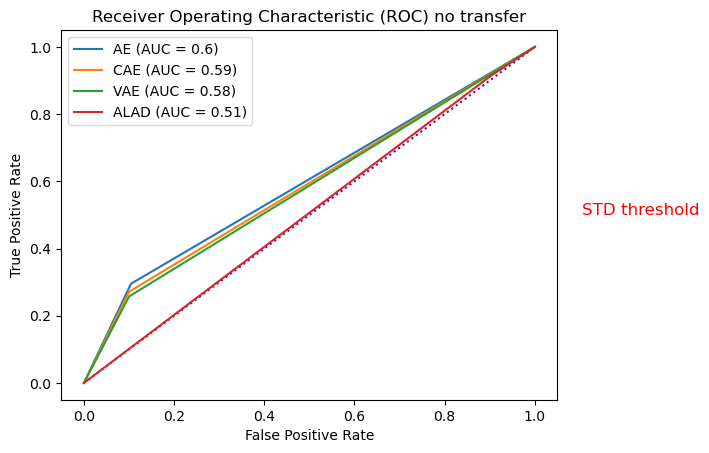

In [65]:
roc_curve_models(avg_ae=ae_std[0], avg_cae=cae_std[0], avg_vae=vae_std[0], avg_alad=alad_std[0], fun_name="STD threshold", all_models=" all models")

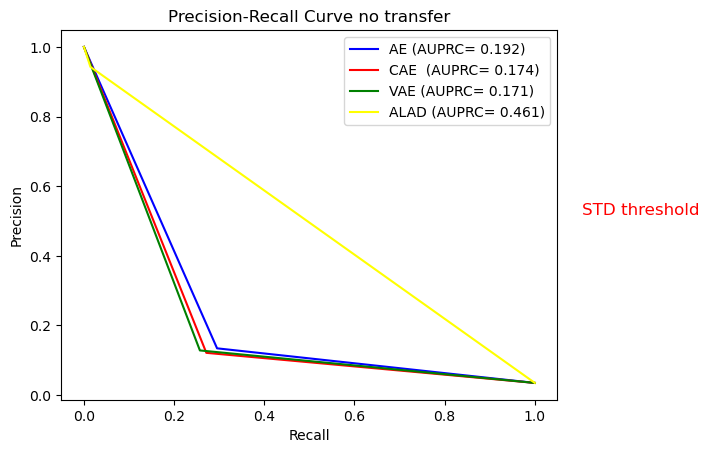

In [67]:
pr_models(avg_ae=ae_std[0], avg_cae=cae_std[0], avg_vae=vae_std[0], avg_alad=alad_std[0], fun_name="STD threshold", all_models=" all-models")

In [68]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    ae, cae, vae, alad = build_models()

    #test different threshold function 
    perc_ae = mean_and_confidence(ae, ae.find_best_percentile_threshold, alpha=0.95, iterations=30, transfer=False)
    perc_cae = mean_and_confidence(cae, cae.find_best_percentile_threshold, alpha=0.95, iterations=30, transfer=False)
    perc_vae = mean_and_confidence(vae, vae.find_best_percentile_threshold, alpha=0.95, iterations=30, transfer=False)
    perc_alad = mean_and_confidence(alad, alad.find_best_percentile_threshold, alpha=0.95, iterations=30, transfer=False)


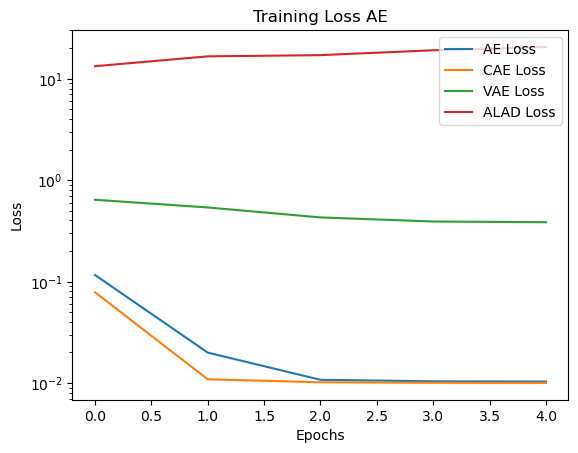

In [69]:
plot_training_loss(perc_ae[3], perc_cae[3], perc_vae[3], perc_alad[3])

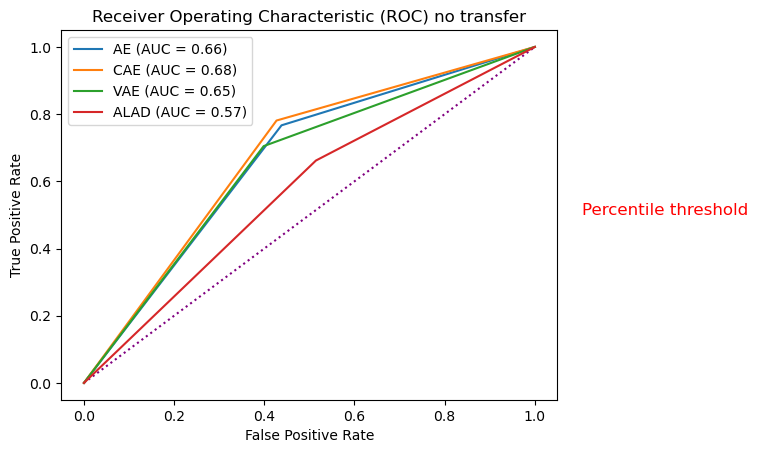

In [70]:
roc_curve_models(avg_ae=perc_ae[0], avg_cae=perc_cae[0], avg_vae=perc_vae[0], avg_alad=perc_alad[0],fun_name="Percentile threshold", all_models=" all-models")

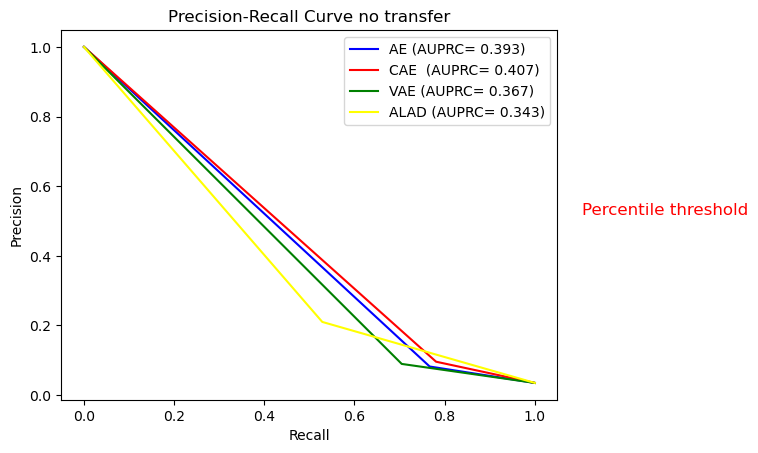

In [71]:
pr_models(avg_ae=perc_ae[0], avg_cae=perc_cae[0], avg_vae=perc_vae[0], avg_alad=perc_alad[0],fun_name="Percentile threshold", all_models=" all-models")

In [82]:
print("_________________ALAD________________")
print_metrics(perc_alad)
print("_________________AE________________")
print_metrics(perc_ae)
print("_________________CAE________________")
print_metrics(perc_cae)
print("_________________VAE________________")
print_metrics(perc_vae)

_________________ALAD________________
          Metric       Mean                                     Interval
0       Accuracy   0.553667    (0.42011518048357155, 0.6872181528497617)
1         Recall   0.595238     (0.4622779031330162, 0.7281982873431743)
2      Precision   0.079176  (0.044268573210095016, 0.11408381273226419)
3            F-1   0.103101    (0.0836399111316625, 0.12256178012393087)
4  Training time  10.048602      (8.066326159426096, 12.030878319155653)
5         AUCROC   0.573698     (0.5474690528860973, 0.5999279369979391)
6          AUPRC   0.714281     (0.6404191245974662, 0.7881427776694496)
_________________AE________________
          Metric      Mean                                   Interval
0       Accuracy  0.569000   (0.4883280021752579, 0.6496719978247417)
1         Recall  0.766667   (0.6775338681848146, 0.8557994651485188)
2      Precision  0.082150    (0.05847582198423905, 0.10582365975338)
3            F-1  0.134198  (0.10918340825242942, 0.1592126809

It seems from these experiments that the what works best to determine the threshold for anomalies is indeed the "standard deviations method". The results from it infact dominate the ones from the "percentile method". 

In [72]:
def z_test(values1, values2, name1, name2, title):

    critical = 1.645
    averages_vae = dict(list(values1[0].items())[-7:])
    keys = list(averages_vae.keys())
    means = pd.DataFrame(averages_vae.values(), columns=["Avg " + name1])
    std = pd.DataFrame(values1[2].values(), columns=["Sigma " + name1])

    averages_vae_no_transfer = dict(list(values2[0].items())[-7:])
    means_no = pd.DataFrame(averages_vae_no_transfer.values(), columns=["Avg " + name2])
    std_no = pd.DataFrame(values2[2].values(), columns=["Sigma " + name2])

    #n is equal to the iterations of the mean_confidence method
    n = 5
    numer = means['Avg ' + name1] - means_no['Avg ' + name2]
    denom = np.sqrt((std['Sigma ' + name1]**2 / n) + (std_no['Sigma ' + name2]**2 / n))
    z_score = numer / denom
    p_value = 2 * (1 - norm.cdf(np.abs(z_score)))

    df = pd.DataFrame({'z-score': z_score, 'p-value': p_value})
    df['Decision'] = ['Reject Null' if z > critical else "Don't reject null" for z in df['z-score']]
    df.index = ["Accuracy", "Recall", "Precision", "F1", "Training time", "AUCROC", "AUPRC"]
    df.name = title
    print(df.head())

# Transfer learning

Make only the AE learn by itself... Then compare the results of the transfer-learned models aginst the ones collected from training each on its own. 

In [73]:
# reinstantiate the models 

ae = Autoencoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
cae = ContractiveAutoEncoder(INPUT_DIM, ENCODING_DIM, lambda_=0.01, learning_rate = LEARNING_RATE)
vae = VariationalAutoEncoder(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
alad = ALAD(INPUT_DIM, ENCODING_DIM, LEARNING_RATE)
ae.build(input_shape=(train_normal_data.shape))
cae.build(input_shape=(train_normal_data.shape))
vae.build(input_shape=(train_normal_data.shape))

In [74]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):

    ae, cae, vae, alad = build_models()


    tr_cae = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95, transfer=True)
    tr_vae = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95, transfer=True)
    tr_alad = mean_and_confidence(alad, alad.find_best_deviations_threshold, alpha=0.95, transfer=True)

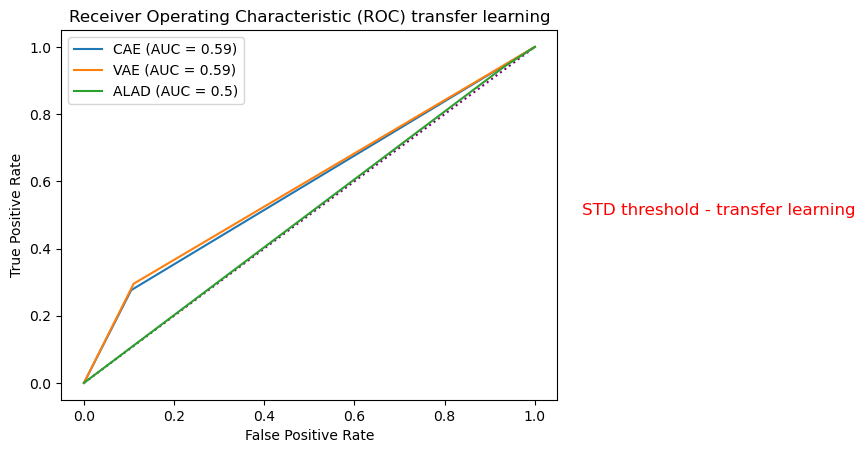

In [75]:
roc_curve_models(avg_cae=tr_cae[0],avg_vae=tr_vae[0], avg_alad=tr_alad[0], fun_name="STD threshold - transfer learning", transfer = "transfer learning", all_models=" just transfer models")

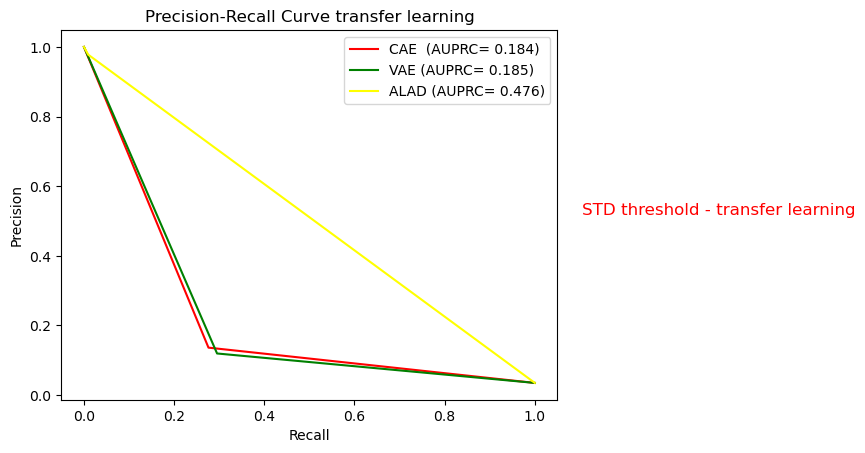

In [76]:
pr_models(avg_cae=tr_cae[0],avg_vae=tr_vae[0], avg_alad=tr_alad[0], fun_name="STD threshold - transfer learning", transfer = "transfer learning", all_models=" just transfer models")

Run mean_and_confidence with 50 epochs for cae, vae and then check if the averages haev significant difference to the ones found with the transfer learning method. 

In [77]:
with open(os.devnull, 'w') as devnull, contextlib.redirect_stdout(devnull):
    notr_cae = mean_and_confidence(cae, cae.find_best_deviations_threshold, alpha=0.95, epochs=50)
    notr_vae = mean_and_confidence(vae, vae.find_best_deviations_threshold, alpha=0.95, epochs=50)
    notr_alad = mean_and_confidence(alad, alad.find_best_deviations_threshold, alpha=0.95, epochs=50)

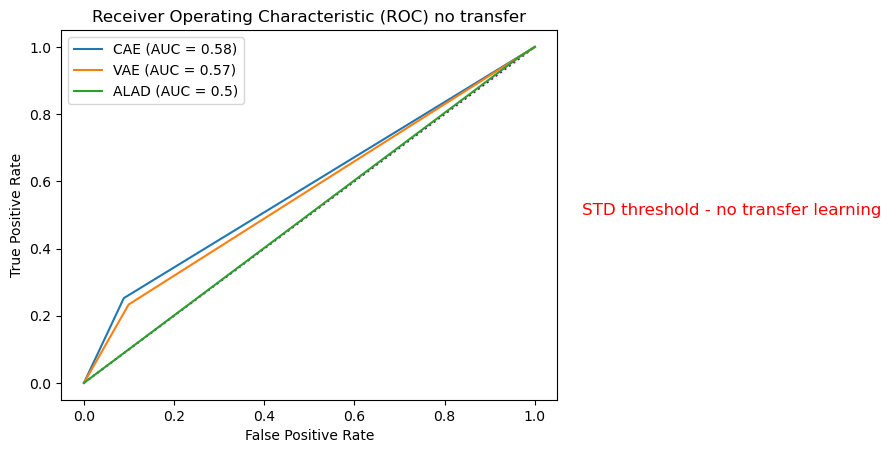

In [78]:
roc_curve_models(avg_cae=notr_cae[0],avg_vae=notr_vae[0], avg_alad=notr_alad[0], fun_name="STD threshold - no transfer learning", all_models=" just transfer models")

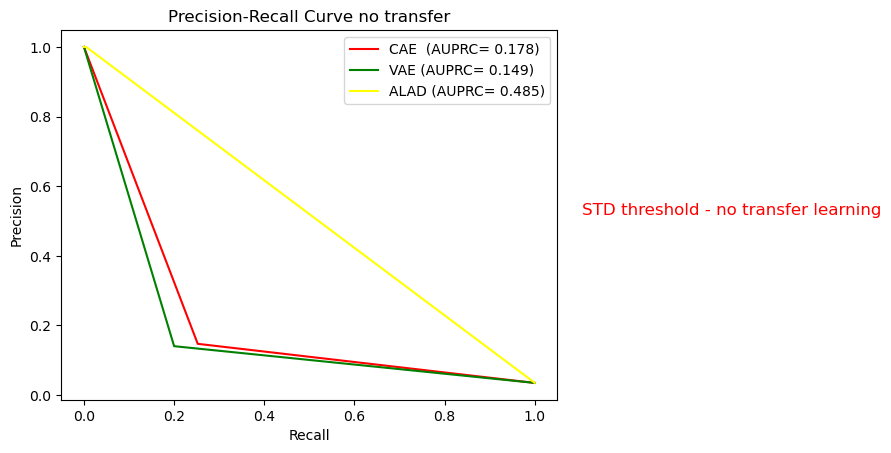

In [79]:
pr_models(avg_cae=notr_cae[0],avg_vae=notr_vae[0], avg_alad=notr_alad[0],fun_name="STD threshold - no transfer learning", all_models=" just transfer models")

Run mean_and_confidence with 200 epochs for cae, vae and then check if the averages haev significant difference to teh ones found with the transfer learning method. 

# Two sample Z-test 
Finally take the difference between teh different average values using the z-score formula. The null hypothesis here is that there is no difference between the two means. The alternative hypothesis will instead be that mean_1 > mean_2.

In [80]:
z_test(tr_cae, notr_cae, "Transfer", "No Transfer", "CAE")
z_test(tr_vae, notr_vae, "Transfer", "No Transfer", "VAE")
z_test(tr_alad, notr_alad, "Transfer", "No Transfer", "ALAD")

                 z-score   p-value           Decision
Accuracy       -0.323842  0.746057  Don't reject null
Recall          0.325887  0.744510  Don't reject null
Precision      -0.170550  0.864578  Don't reject null
F1             -0.041372  0.966999  Don't reject null
Training time -54.936069  0.000000  Don't reject null
                 z-score   p-value           Decision
Accuracy       -0.956652  0.338743  Don't reject null
Recall          0.855608  0.392215  Don't reject null
Precision       0.200259  0.841278  Don't reject null
F1              0.400544  0.688756  Don't reject null
Training time -85.608385  0.000000  Don't reject null
                z-score   p-value           Decision
Accuracy      -0.237023  0.812639  Don't reject null
Recall         0.242536  0.808365  Don't reject null
Precision      0.095783  0.923693  Don't reject null
F1             0.206614  0.836311  Don't reject null
Training time -1.016443  0.309419  Don't reject null


# Performance metrics

In [81]:
print("____________ AE_____________________")
z_test(ae_std, perc_ae, "STD", "PERC", "AE")
print("____________ CAE_____________________")
z_test(cae_std, perc_cae, "STD", "PERC", "CAE")
print("____________ VAE_____________________")
z_test(vae_std, perc_vae, "STD", "PERC", "VAE")
print("____________ ALAD_____________________")
z_test(alad_std, perc_alad, "STD", "PERC", "ALAD")

____________ AE_____________________
                z-score   p-value           Decision
Accuracy       2.988112  0.002807        Reject Null
Recall        -3.676768  0.000236  Don't reject null
Precision      1.113710  0.265404  Don't reject null
F1             0.497980  0.618498  Don't reject null
Training time -1.545292  0.122276  Don't reject null
____________ CAE_____________________
                z-score       p-value           Decision
Accuracy       3.057206  2.234104e-03        Reject Null
Recall        -3.828761  1.287900e-04  Don't reject null
Precision      0.454015  6.498182e-01  Don't reject null
F1            -0.005090  9.959390e-01  Don't reject null
Training time -7.283231  3.259615e-13  Don't reject null
____________ VAE_____________________
                 z-score   p-value           Decision
Accuracy        3.019047  0.002536        Reject Null
Recall         -3.787368  0.000152  Don't reject null
Precision       0.575705  0.564814  Don't reject null
F1         